# 01 · Data Cleansing & Pre-processing

**Project:** FinSight — Annual Report Analyzer (self-hosted ML)

This notebook turns raw annual-report PDFs into two clean, analysis-ready datasets:

| Dataset | Unit of observation | Used for |
|---|---|---|
| `pages_clean.jsonl` | one PDF page | **PageClassifier** (page-type classification) and the KPI-NER training corpus |
| `kpis_clean.csv` | one KPI of one report | KPI EDA, the financial-health classifier, and the KPI-accuracy baseline |

**Pipeline:** raw extraction → quality audit → text cleansing → noise removal → weak labelling →
feature engineering → class-imbalance handling → leakage-free split → KPI cleansing → export.

Raw data comes from `python -m ml.preprocess.extract_raw`. It reads every processed report in the app DB
with PyMuPDF and exports the KPIs found by the current rule-based extractor.

In [1]:
import json
import warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight

from ml.paths import RAW_DIR, PROCESSED_DIR, REPORTS_DIR, FIGURES_DIR
from ml.preprocess.text_clean import clean_document, normalize_unicode, page_features
from ml.preprocess.label_pages import label_document, scope_of, LABELS
from ml.preprocess.kpi_clean import detect_report_unit_with_fallback, clean_kpis, iqr_outliers

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")
SEED = 42

## 1. Load the raw data

In [2]:
pages = pd.read_json(RAW_DIR / "pages_raw.jsonl", lines=True)
reports = pd.read_csv(RAW_DIR / "reports.csv")
kpis_raw = pd.read_csv(RAW_DIR / "kpis_raw.csv")

print(f"pages: {pages.shape}   reports: {reports.shape}   kpis: {kpis_raw.shape}")
reports

pages: (2258, 8)   reports: (6, 6)   kpis: (120, 12)


,report_id,file_name,company,sector,fiscal_year,n_pages
0,1c9e78bb-0f90-4881-9af9-83979c582e1a,FY26.pdf,ADARSH PLANT PROTECT LIMITED,Unknown,2026,111
1,305f94a3-cb9e-41c1-816b-6b542d8ed933,Adani.pdf,Adani Enterprises Ltd.,Metals & Mining,2026,396
2,9a88fab0-2586-44d2-b151-c9c65e144db9,adani 25.pdf,Adani Enterprises Ltd.,Metals & Mining,2025,610
3,8566cb3c-d316-44fb-9636-7c2f391c6f48,Airtel FY2026.pdf,Bharti Airtel Ltd.,Telecommunication,2026,303
4,9820853e-5875-42a8-8001-2ad123f1b432,HAL FY2026.pdf,Hindustan Aeronautics Ltd.,Capital Goods,2026,414
5,45b2e41b-a5b7-4f11-9374-a46e2fdfd974,HAL FY2025.pdf,Hindustan Aeronautics Ltd.,Capital Goods,2025,424


In [3]:
pages.drop(columns="raw_text").head()

,report_id,company,sector,fiscal_year,page_number,n_pages,has_images
0,1c9e78bb-0f90-4881-9af9-83979c582e1a,ADARSH PLANT PROTECT LIMITED,Unknown,2026,1,111,1
1,1c9e78bb-0f90-4881-9af9-83979c582e1a,ADARSH PLANT PROTECT LIMITED,Unknown,2026,2,111,1
2,1c9e78bb-0f90-4881-9af9-83979c582e1a,ADARSH PLANT PROTECT LIMITED,Unknown,2026,3,111,0
3,1c9e78bb-0f90-4881-9af9-83979c582e1a,ADARSH PLANT PROTECT LIMITED,Unknown,2026,4,111,0
4,1c9e78bb-0f90-4881-9af9-83979c582e1a,ADARSH PLANT PROTECT LIMITED,Unknown,2026,5,111,0


In [4]:
pages.dtypes.to_frame("dtype").T

,report_id,company,sector,fiscal_year,page_number,n_pages,has_images,raw_text
dtype,str,str,str,int64,int64,int64,int64,str


## 2. Data-quality audit (before cleaning)

We measure each known noise source *before* touching the data, so its effect can be shown afterwards.

In [5]:
raw = pages["raw_text"]
audit = pd.Series({
    "empty pages (< 50 chars)":             (raw.str.strip().str.len() < 50).sum(),
    "pages with ligatures (ﬁ ﬂ ﬀ)":         raw.str.contains("[ﬀ-ﬆ]").sum(),
    "pages with legacy ₹ glyph (`)":         raw.str.contains(r"`\s*(?:in\b|\d)", regex=True).sum(),
    "pages with 'Rs.' / 'INR' notation":     raw.str.contains(r"\bRs\.?\s?\d|\bINR\s?\d", regex=True).sum(),
    "pages with unicode dashes (– — −)":     raw.str.contains("[–—−]").sum(),
    "pages with curly quotes (’ ”)":         raw.str.contains("[’”]").sum(),
    "pages with line-break hyphenation":     raw.str.contains(r"[a-z]-\n[a-z]", regex=True).sum(),
    "exact-duplicate pages":                 raw.duplicated().sum(),
    "missing values (any column)":           pages.isna().sum().sum(),
}, name="count").to_frame()
audit["% of pages"] = (100 * audit["count"] / len(pages)).round(1)
audit

,count,% of pages
empty pages (< 50 chars),56,2.5
pages with ligatures (ﬁ ﬂ ﬀ),88,3.9
pages with legacy ₹ glyph (`),851,37.7
pages with 'Rs.' / 'INR' notation,19,0.8
pages with unicode dashes (– — −),422,18.7
pages with curly quotes (’ ”),1247,55.2
pages with line-break hyphenation,267,11.8
exact-duplicate pages,4,0.2
missing values (any column),0,0.0


**Running headers / footers.** Report pages repeat the company name, report title and section name at
the top or bottom. The cleaner flags any line that appears at a page edge on at least 30% of a report's
pages. Digits are normalised first, so "Annual Report 2025-26 | 14" and "… | 15" count as the same line.

In [6]:
from ml.preprocess.text_clean import find_running_lines

for rid, g in pages.groupby("report_id", sort=False):
    counts = find_running_lines(g["raw_text"].tolist())
    top = [(line, round(c / len(g), 2)) for line, c in counts.most_common(4)]
    print(f"{g['company'].iat[0][:28]:<28} {g['fiscal_year'].iat[0]}  →  {top}")

ADARSH PLANT PROTECT LIMITED 2026  →  [('#', 0.99), ('#.#', 0.14), ('th', 0.13), ('notes to financial statements', 0.12)]
Adani Enterprises Ltd.       2026  →  [('statements', 0.88), ('adani enterprises limited', 0.81), ('integrated annual report #-#', 0.63), ('financial', 0.32)]
Adani Enterprises Ltd.       2025  →  [('#', 0.63), ('adani enterprises limited', 0.59), ('integrated annual report #-#', 0.59), ('portfolio overview', 0.35)]
Bharti Airtel Ltd.           2026  →  [('financial statements', 0.76), ('statutory reports', 0.59), ('management discussion & analysis', 0.57), ('#', 0.41)]
Hindustan Aeronautics Ltd.   2026  →  [('#', 0.96), ('hindustan aeronautics limited', 0.51), ('notes to the consolidated financial statements for the year ended march #, #', 0.17), ('(` in lakhs)', 0.17)]
Hindustan Aeronautics Ltd.   2025  →  [('#', 0.99), ('hindustan aeronautics limited', 0.5), ('annual report #-#', 0.5), ('notes to the consolidated financial statements for the year ended march #, #

## 3. Text cleansing

`clean_document` (in `ml/preprocess/text_clean.py`) applies these steps to every report:
1. **Unicode normalisation (NFKC):** ligatures become plain letters (ﬁ → fi) and full-width characters become ASCII.
2. **Look-alike characters unified:** dashes become `-`, curly quotes become `'`/`"`, and `Rs.`/`INR`/the legacy backtick glyph become `₹`.
3. **Running header/footer removal:** only lines at page edges are checked.
4. **Page-number removal:** also restricted to page edges, because bare numbers mid-page are table cells.
5. **De-hyphenation** across line breaks (`opera-\ntions` → `operations`).
6. **Whitespace normalisation.**

In [7]:
# Sorted so each report's pages are contiguous and in order (groupby below preserves that order)
pages = pages.sort_values(["report_id", "page_number"]).reset_index(drop=True)
clean_rows, stat_rows = [], []
for rid, g in pages.groupby("report_id", sort=False):
    result = clean_document(g["raw_text"].tolist())
    clean_rows += result.pages
    stat_rows += [st.__dict__ for st in result.stats]

stats = pd.DataFrame(stat_rows)
pages = pd.concat([pages, stats], axis=1)
pages["clean_text"] = clean_rows

summary = stats[["chars_before", "chars_after", "header_footer_lines", "page_number_lines",
                 "hyphen_joins", "unicode_fixes"]].sum()
summary["% characters removed"] = round(100 * (1 - summary.chars_after / summary.chars_before), 2)
summary.to_frame("total")

,total
chars_before,8142402.00
chars_after,7836648.00
header_footer_lines,3618.00
page_number_lines,1779.00
hyphen_joins,544.00
unicode_fixes,261839.00
% characters removed,3.76


### Before / after: one page

In [8]:
ex = pages.loc[(pages.header_footer_lines >= 2) & (pages.page_number_lines >= 1) & (pages.hyphen_joins >= 1)
               & (pages.unicode_fixes >= 1)].iloc[0]
print(f"── {ex.company}, page {ex.page_number} ── BEFORE ──\n{ex.raw_text[:900]}")
print(f"\n── AFTER ──\n{ex.clean_text[:900]}")

── Adani Enterprises Ltd., page 395 ── BEFORE ──
Abbreviations
Full Forms
km
kilometres
KPI
Key Performance Indicator
KT
Kilo Tonnes
KTPA
Killo Tonnes Per Annum
kWh
Kilowatt Hours
LLP
Limited Liability Partnership
LNG
Liquefied Natural Gas
LRTC
Legal Regulatory & Tax Committee
LSSR
Life Saving Safety Rules
LTIFR
Lost Time Injury Frequency Rate
MAAS
Management Audit & Assurance 
Services
MCA
Model Concession Agreement
MCM
Million Cubic Metres
MDO
Mine Developer and Operator
MEP
Mechanical, Electrical, and Plumbing
MLD
Millions Liter per Day
MMSCM
Million Metric Standard Cubic Meter 
MMT
Million Metric Tonnes 
MMTPA
Million Metric Tonnes Per Annum
MNRE
Ministry of New & Renewable Energy 
MoC
Ministry of Coal
MoRTH
Ministry of Road Transport and 
Highways
MPL
Mundra Petrochem Limited
MPPA
Mining Plan Preparing Agency
MRF
Material Recovery Facility
MRO
Maintenance, Repair, and Overhaul
MSEL
Mundra Solar Energy Limited
MSME
Micro, Small & M

── AFTER ──
Abbreviations
Full Forms
km
kilometre

In [9]:
check = pd.Series({
    "ligatures remaining":            pages.clean_text.str.contains("[ﬀ-ﬆ]").sum(),
    "legacy ₹ glyphs remaining":      pages.clean_text.str.contains(r"`\s*(?:in\b|\d)", regex=True).sum(),
    "unicode dashes remaining":       pages.clean_text.str.contains("[–—−]").sum(),
    "line-break hyphenations left":   pages.clean_text.str.contains(r"[a-z]-\n[a-z]", regex=True).sum(),
}, name="after cleaning")
check.to_frame()

,after cleaning
ligatures remaining,0
legacy ₹ glyphs remaining,0
unicode dashes remaining,0
line-break hyphenations left,8


## 4. Noise removal: empty and duplicate pages

* **Near-empty pages** (under 50 characters after cleaning) are covers, full-page photos or divider
  pages. They carry no text signal for a text classifier.
* **Duplicate pages** inside the same report (identical cleaned text) are dropped so they do not get
  extra weight in training.

In [10]:
n0 = len(pages)
pages["is_empty"] = pages.clean_text.str.len() < 50
pages["is_duplicate"] = pages.duplicated(["report_id", "clean_text"]) & ~pages.is_empty

removed = pd.Series({
    "near-empty pages": pages.is_empty.sum(),
    "  of which contain images": (pages.is_empty & (pages.has_images == 1)).sum(),
    "duplicate pages": pages.is_duplicate.sum(),
})
print(removed.to_string())

near-empty pages             57
  of which contain images    44
duplicate pages               2


## 5. Weak labelling (page type)

There is no hand-labelled dataset of Indian annual-report pages, so labels are produced with **weak
supervision** (`ml/preprocess/label_pages.py`):
* Search the top of each page for section-heading patterns, e.g. *"Statement of Profit and Loss"* or
  *"Balance Sheet as at"*, and take the earliest match.
* Narrative sections print their heading only on the first page, so their label is **carried forward**
  until the next heading.
* Labelling runs on the *normalised but un-stripped* text, because running headers such as
  "Management Discussion & Analysis" are strong section signals.

`label_source` keeps track of where each label came from. A held-out sample will be hand-corrected into
a **gold** set, which is used to evaluate the classifier honestly.

In [11]:
labels, sources, scopes = [], [], []
for rid, g in pages.groupby("report_id", sort=False):
    norm = [normalize_unicode(t) for t in g["raw_text"]]
    for (label, src), t in zip(label_document(norm), norm):
        labels.append(label)
        sources.append(src)
        scopes.append(scope_of(t))
pages["label"], pages["label_source"], pages["scope"] = labels, sources, scopes

pd.crosstab(pages.label, pages.label_source, margins=True).loc[LABELS + ["All"]]

label_source,carry,default,heading,All
label,,,,
balance_sheet,0,0,14,14
profit_loss,0,0,31,31
cash_flow,0,0,13,13
equity_changes,0,0,9,9
notes,195,0,634,829
auditor_report,154,0,22,176
directors_report,246,0,16,262
mda,97,0,9,106
corporate_governance,210,0,18,228


## 6. Feature engineering

Structural features are computed from the cleaned text. Together with TF-IDF vectors (built in notebook
03), they are the inputs to the page classifier.

| feature | why it helps |
|---|---|
| `n_words`, `n_lines`, `avg_line_len` | narrative pages have long lines; statement pages have short tabular ones |
| `n_numbers`, `digit_ratio`, `numeric_line_ratio` | financial statements are dense with numbers |
| `has_rupee` | currency declarations appear on statement and notes pages |
| `rel_position` | the order of sections is similar across reports (narrative first, then financials) |
| `scope` | standalone vs consolidated statements |

In [12]:
feat = pd.DataFrame([page_features(t) for t in pages.clean_text])
pages = pd.concat([pages, feat], axis=1)
pages["rel_position"] = (pages.page_number / pages.n_pages).round(4)
FEATURES = list(feat.columns) + ["rel_position"]
pages[FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
n_chars,2258.0,3470.615,2079.680,0.000,1938.000,3159.000,4533.500,11687.000
n_words,2258.0,530.788,309.997,0.000,307.000,481.000,699.750,1764.000
n_lines,2258.0,131.398,101.467,0.000,72.000,109.000,163.750,1055.000
n_numbers,2258.0,56.827,66.155,0.000,16.000,40.000,76.000,821.000
digit_ratio,2258.0,0.067,0.077,0.000,0.012,0.033,0.102,0.792
numeric_line_ratio,2258.0,0.158,0.192,0.000,0.006,0.052,0.286,0.964
avg_line_len,2258.0,31.151,20.184,0.000,15.860,27.335,40.935,106.690
has_rupee,2258.0,0.450,0.498,0.000,0.000,0.000,1.000,1.000
rel_position,2258.0,0.501,0.289,0.002,0.251,0.502,0.751,1.000


## 7. Final page dataset and class imbalance

pages: 2258 raw → 2199 after noise removal (59 removed)
imbalance ratio (largest / smallest class) = 92 : 1


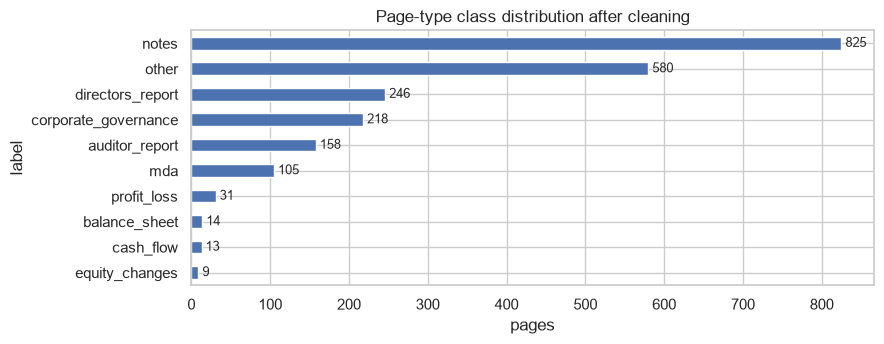

In [13]:
# Top of the page *before* running-header removal: section headers are the strongest page-type cue,
# so they are kept as a separate model input (`head_text`); available identically at inference time.
pages["head_text"] = pages.raw_text.map(lambda t: normalize_unicode(t)[:400].lower())

data = pages[~pages.is_empty & ~pages.is_duplicate].reset_index(drop=True)
print(f"pages: {n0} raw → {len(data)} after noise removal ({n0 - len(data)} removed)")

counts = data.label.value_counts().reindex(LABELS)
imbalance_ratio = counts.max() / counts.min()
print(f"imbalance ratio (largest / smallest class) = {imbalance_ratio:.0f} : 1")

fig, ax = plt.subplots(figsize=(9, 3.6))
counts.sort_values().plot.barh(ax=ax, color=sns.color_palette("deep")[0])
ax.set_title("Page-type class distribution after cleaning")
ax.set_xlabel("pages")
for i, v in enumerate(counts.sort_values()):
    ax.text(v + 5, i, str(v), va="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_class_distribution.png", dpi=130)
plt.show()

The classes are **heavily imbalanced**. Financial statements (balance sheet, P&L, cash flow) take up only
a few pages per report, while notes and narrative take hundreds. Plain accuracy would reward a model that
never predicts the rare statement classes, even though those are the pages KPI extraction depends on.

Two mitigations:
1. **Class weights** inversely proportional to frequency (`class_weight="balanced"`), computed below and
   passed to every model in notebook 03.
2. **Evaluation on macro-F1** rather than accuracy, so every class counts equally.

SMOTE oversampling is compared as an alternative in notebook 03 and applied only to the training fold,
never before splitting.

In [14]:
present = [l for l in LABELS if l in set(data.label)]
weights = compute_class_weight("balanced", classes=np.array(present), y=data.label)
class_weights = dict(zip(present, np.round(weights, 3)))
pd.Series(class_weights, name="class weight").to_frame().T

,balance_sheet,profit_loss,cash_flow,equity_changes,notes,auditor_report,directors_report,mda,corporate_governance,other
class weight,15.707,7.094,16.915,24.433,0.267,1.392,0.894,2.094,1.009,0.379


## 8. Leakage-free train / validation / test split

Pages of the same report share templates, fonts and running text. A random page-level split would
therefore leak information and inflate scores. We split **by company**, so every report of a company ends
up on the same side of the split.

With few companies, one random group split can be badly unbalanced (e.g. a test set larger than the
training set). So we draw many random group partitions and keep the one whose **page** proportions are
closest to 70 / 10 / 20. The search only looks at group sizes, never at labels or scores, so it adds
no leakage.

In [15]:
TARGET = {"train": 0.70, "val": 0.10, "test": 0.20}
companies = data.company.unique()
pages_per_company = data.company.value_counts()
rng = np.random.default_rng(SEED)

best, best_err = None, np.inf
for _ in range(500):
    perm = rng.permutation(companies)
    for i in range(1, len(perm) - 1):
        for j in range(i + 1, len(perm)):
            assign = {**{c: "train" for c in perm[:i]}, **{c: "val" for c in perm[i:j]},
                      **{c: "test" for c in perm[j:]}}
            share = pages_per_company.groupby(pd.Series(assign)).sum() / len(data)
            err = sum(abs(share.get(s, 0) - t) for s, t in TARGET.items())
            if err < best_err:
                best, best_err = assign, err

data["split"] = data.company.map(best)
print(f"chosen split (L1 distance from 70/10/20 = {best_err:.3f}):")
print((data.split.value_counts(normalize=True).reindex(TARGET).round(3)).to_string())

split_table = data.groupby(["split", "company"]).size().unstack(0).fillna(0).astype(int)
split_table.loc["TOTAL"] = split_table.sum()
split_table

chosen split (L1 distance from 70/10/20 = 0.235):
split
train    0.818
val      0.045
test     0.137


split,test,train,val
company,,,
ADARSH PLANT PROTECT LIMITED,0,0,100
Adani Enterprises Ltd.,0,1001,0
Bharti Airtel Ltd.,301,0,0
Hindustan Aeronautics Ltd.,0,797,0
TOTAL,301,1798,100


In [16]:
assert not set(data[data.split == "train"].company) & set(data[data.split == "test"].company), "company leakage!"
pd.crosstab(data.label, data.split).reindex(LABELS)

split,test,train,val
label,,,
balance_sheet,0,13,1
profit_loss,1,30,0
cash_flow,0,13,0
equity_changes,0,8,1
notes,118,673,34
auditor_report,15,130,13
directors_report,11,235,0
mda,68,32,5
corporate_governance,48,128,42


## 9. KPI cleansing

The existing rule-based extractor stores **every** KPI as "₹ crore". The audit below shows three
kinds of problem with that:
* **Scale:** HAL reports in *₹ lakh* and Airtel in *₹ million*, so their values are inflated 10–100×.
* **Misreads:** "Revenue from Operations" = 4.89 is a growth % or a note number, not revenue.
* **Wrong cell:** ratios stored as percentages (D/E = 335.2), values copied from the comparative
  (prior-year) column, and impossible values (EPS = 1.25 × 10⁹).

### 9.1 Detect each report's reporting unit
Reports declare their unit, e.g. *"(₹ in Lakhs)"*. We count declarations on the financial-statement pages
found in step 5, and fall back to the whole report when there is too little evidence.

In [17]:
FIN = {"balance_sheet", "profit_loss", "cash_flow", "equity_changes", "notes"}
unit_rows, report_units = [], {}
for rid, g in pages.groupby("report_id", sort=False):
    norm = [normalize_unicode(t) for t in g.raw_text]
    fin = [t for t, l in zip(norm, g.label) if l in FIN]
    unit, counts, scope = detect_report_unit_with_fallback(fin, norm)
    report_units[rid] = unit
    unit_rows.append({"company": g.company.iat[0], "fiscal_year": g.fiscal_year.iat[0],
                      "detected_unit": unit, "evidence_from": scope, "declaration_counts": counts})
pd.DataFrame(unit_rows)

,company,fiscal_year,detected_unit,evidence_from,declaration_counts
0,ADARSH PLANT PROTECT LIMITED,2026,lakh,statements,{'lakh': 24}
1,Adani Enterprises Ltd.,2026,crore,statements,{'crore': 222}
2,Hindustan Aeronautics Ltd.,2025,lakh,statements,{'lakh': 287}
3,Bharti Airtel Ltd.,2026,million,whole_report,"{'million': 31, 'billion': 1, 'thousand': 4}"
4,Hindustan Aeronautics Ltd.,2026,lakh,statements,{'lakh': 208}
5,Adani Enterprises Ltd.,2025,crore,statements,{'crore': 329}


### 9.2 Apply the cleansing rules (`ml/preprocess/kpi_clean.py`)
Every change goes into an audit log, so each corrected value can be traced back to the rule and the reason.

In [18]:
kpis, audit_log = clean_kpis(kpis_raw, report_units)
audit_log.groupby("rule").size().rename("changes").to_frame().T

rule,consistency,derived,domain_range,recompute,scale,sign,stale_copy
changes,14,5,1,4,68,2,3


In [19]:
(audit_log[audit_log.rule != "scale"]
 .assign(company=lambda d: d.company.str[:18])
 [["rule", "company", "fiscal_year", "kpi", "old", "new", "reason"]])

,rule,company,fiscal_year,kpi,old,new,reason
68,sign,Hindustan Aeronaut,2026,Capital Expenditure (CapEx),-1.485200e+03,1485.2000,cash-flow outflow sign dropped; CapEx stored as a positive amount
69,sign,Hindustan Aeronaut,2025,Capital Expenditure (CapEx),-9.300900e+02,930.0900,cash-flow outflow sign dropped; CapEx stored as a positive amount
70,stale_copy,Adani Enterprises,2026,Operating Profit (EBIT),1.544525e+04,NaN,identical to prior year — extractor read the comparative column
71,stale_copy,Adani Enterprises,2026,Revenue from Operations,1.137000e+01,NaN,identical to prior year — extractor read the comparative column
72,stale_copy,Hindustan Aeronaut,2026,Operating Cash Flow,1.718327e+04,NaN,identical to prior year — extractor read the comparative column
73,consistency,ADARSH PLANT PROTE,2026,Revenue from Operations,5.000000e-02,NaN,must be 50–100% of Total Revenue; likely a growth % or note number (is 0.4% of Total R...
74,recompute,ADARSH PLANT PROTE,2026,Debt-to-Equity Ratio,3.352000e+02,3.3520,stored as a percentage — Debt (Total Borrowings)/Total Equity / Shareholders Equity = ...
75,recompute,Adani Enterprises,2026,Current Ratio,1.730000e+00,1.3460,disagrees with Current Assets/Current Liabilities = 1.35
76,derived,Adani Enterprises,2026,Debt-to-Equity Ratio,NaN,0.5288,missing — derived as Debt (Total Borrowings) / Total Equity / Shareholders Equity
77,consistency,Hindustan Aeronaut,2025,Revenue from Operations,2.500000e-01,NaN,must be 50–100% of Total Revenue; likely a growth % or note number (is 0.0% of Total R...


### 9.3 Before vs after

In [20]:
def pivot(df, col):
    return (df.assign(report=df.company.str.split().str[0] + " " + df.fiscal_year.astype(str))
              .pivot_table(index="name", columns="report", values=col, aggfunc="first"))

headline = ["Total Revenue", "Profit After Tax (PAT) / Net Profit", "Total Assets",
            "Total Equity / Shareholders Equity", "Current Ratio", "Debt-to-Equity Ratio"]
before = pivot(kpis_raw, "value").reindex(headline)
after = pivot(kpis, "value").reindex(headline)
pd.concat({"BEFORE (raw)": before, "AFTER (₹ crore / x)": after}, axis=1).round(2)

BEFORE (raw)                                                                 AFTER (₹ crore / x)                        \
report                               ADARSH 2026 Adani 2025 Adani 2026 Bharti 2026 Hindustan 2025 Hindustan 2026         ADARSH 2026 Adani 2025 Adani 2026   
name                                                                                                                                                         
Total Revenue                            1203.73  100365.08  102943.24   2109728.0      3354645.0      3679354.0               12.04  100365.08  102943.24   
Profit After Tax (PAT) / Net Profit        -2.38   50313.97   11378.06    400507.0       838494.0       911560.0               -0.02        NaN   11378.06   
Total Assets                             1027.13  198135.54  261600.35   5521516.0     10626685.0     13241459.0               10.27  198135.54  261600.35   
Total Equity / Shareholders Equity         30.60  125706.80  163970.84   1490566.0      3498517.0      4104460.0                0.31  125706.80  163970.84   
Current Ratio                               1.53       1.73       1.73         NaN            NaN            NaN                1.53       1.25       1.35   
Debt-to-Equity Ratio                      335.20        NaN        NaN        37.0            NaN            NaN                3.35       0.61       0.53   

                                                                               
report                              Bharti 2026 Hindustan 2025 Hindustan 2026  
name                                                                           
Total Revenue                         210972.80       33546.45       36793.54  
Profit After Tax (PAT) / Net Profit    40050.70        8384.94        9115.60  
Total Assets                          552151.60      106266.85      132414.59  
Total Equity / Shareholders Equity    149056.60       34985.17       41044.60  
Current Ratio                              1.72           2.04           2.61  
Debt-to-Equity Ratio                       1.01            NaN            NaN

### 9.4 Missing values

Every KPI that cleansing rejects becomes `NaN`, and some KPIs were never found. Missingness is **not
random**: per-share and ratio KPIs are missing more often because they appear in narrative highlights
rather than in tables. Policy:
* **Ratios** are *derived* from their components wherever possible (already done in rule 6c). This is
  domain imputation, not statistical imputation.
* For the tabular financial-health model, the remaining gaps are imputed with the **median within the
  same sector**, and a `*_was_missing` indicator is added. This happens inside the training pipeline,
  after the split.
* Nothing is imputed in the EDA dataset, so the EDA shows the true missingness.

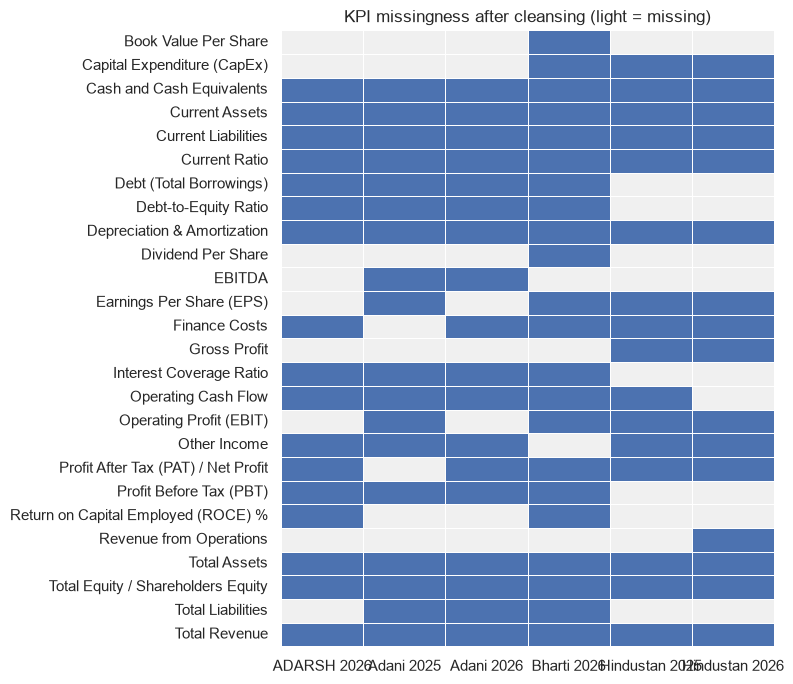

overall KPI missingness: 31.4%


In [21]:
miss = pivot(kpis, "value").isna()
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(miss, cbar=False, cmap=["#4c72b0", "#f0f0f0"], linewidths=.4, ax=ax)
ax.set_title("KPI missingness after cleansing (light = missing)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_kpi_missingness.png", dpi=130)
plt.show()
print(f"overall KPI missingness: {miss.values.mean():.1%}")

### 9.5 Outliers: Tukey IQR rule on log₁₀ values

Monetary KPIs span 5+ orders of magnitude, from ₹0.2 crore (a small-cap) to ₹5,50,000 crore (Airtel's
total assets). An IQR rule on raw values would flag every large company, so it is applied to
**log₁₀ |value|** within each KPI. Values that survive the domain rules but fall outside the log-IQR fence
are **flagged, not dropped**: a small-cap company is a legitimate outlier.

In [22]:
money = kpis[kpis.unit == "₹ crore"].dropna(subset=["value"]).copy()
money["log_outlier"] = money.groupby("name")["value"].transform(
    lambda s: iqr_outliers(s) if s.notna().sum() >= 4 else False)
money.loc[money.log_outlier, ["company", "fiscal_year", "name", "value"]]

,company,fiscal_year,name,value
0,ADARSH PLANT PROTECT LIMITED,2026,Total Revenue,12.04
1,ADARSH PLANT PROTECT LIMITED,2026,Other Income,0.04
3,ADARSH PLANT PROTECT LIMITED,2026,Profit After Tax (PAT) / Net Profit,-0.02
7,ADARSH PLANT PROTECT LIMITED,2026,Cash and Cash Equivalents,0.23
8,ADARSH PLANT PROTECT LIMITED,2026,Current Assets,7.71
9,ADARSH PLANT PROTECT LIMITED,2026,Total Assets,10.27
10,ADARSH PLANT PROTECT LIMITED,2026,Total Equity / Shareholders Equity,0.31
11,ADARSH PLANT PROTECT LIMITED,2026,Current Liabilities,5.54
12,ADARSH PLANT PROTECT LIMITED,2026,Depreciation & Amortization,0.53
13,ADARSH PLANT PROTECT LIMITED,2026,Operating Cash Flow,1.07


## 10. Export

In [23]:
keep = ["report_id", "company", "sector", "fiscal_year", "page_number", "n_pages", "label", "label_source",
        "scope", "split", "clean_text", "head_text"] + FEATURES
data[keep].to_json(PROCESSED_DIR / "pages_clean.jsonl", orient="records", lines=True, force_ascii=False)
kpis.to_csv(PROCESSED_DIR / "kpis_clean.csv", index=False)
audit_log.to_csv(PROCESSED_DIR / "kpi_audit_log.csv", index=False)
(PROCESSED_DIR / "class_weights.json").write_text(json.dumps(class_weights, indent=2), encoding="utf-8")

summary_out = {
    "raw_pages": int(n0),
    "clean_pages": int(len(data)),
    "reports": int(reports.shape[0]),
    "companies": int(data.company.nunique()),
    "chars_removed_pct": float(summary["% characters removed"]),
    "header_footer_lines_removed": int(summary.header_footer_lines),
    "page_number_lines_removed": int(summary.page_number_lines),
    "hyphen_joins": int(summary.hyphen_joins),
    "empty_pages_removed": int(pages.is_empty.sum()),
    "duplicate_pages_removed": int(pages.is_duplicate.sum()),
    "quality_audit": {k: int(v) for k, v in audit["count"].items()},
    "class_counts": {k: int(v) for k, v in counts.items()},
    "imbalance_ratio": round(float(imbalance_ratio), 1),
    "class_weights": {k: float(v) for k, v in class_weights.items()},
    "splits": {s: int(n) for s, n in data.split.value_counts().items()},
    "split_companies": {s: sorted(g.company.unique().tolist()) for s, g in data.groupby("split")},
    "kpi_rows_raw": int(len(kpis_raw)),
    "kpi_rows_clean": int(kpis.value.notna().sum()),
    "kpi_rule_counts": {k: int(v) for k, v in audit_log.groupby("rule").size().items()},
    "report_units": {r["company"] + " " + str(r["fiscal_year"]): r["detected_unit"] for r in unit_rows},
    "kpi_missingness": round(float(miss.values.mean()), 3),
}
(REPORTS_DIR / "preprocessing_summary.json").write_text(json.dumps(summary_out, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps({k: summary_out[k] for k in ("raw_pages", "clean_pages", "splits", "kpi_rule_counts")}, indent=1))

{
 "raw_pages": 2258,
 "clean_pages": 2199,
 "splits": {
  "train": 1798,
  "test": 301,
  "val": 100
 },
 "kpi_rule_counts": {
  "consistency": 14,
  "derived": 5,
  "domain_range": 1,
  "recompute": 4,
  "scale": 68,
  "sign": 2,
  "stale_copy": 3
 }
}


## Summary

| Step | Result |
|---|---|
| Text cleansing | Unicode/ligature/₹ normalisation, running headers and footers, page numbers, hyphenation (see table §3) |
| Noise removal | Near-empty and duplicate pages dropped (§4) |
| Labels | 10 page types by weak supervision, with provenance recorded (§5) |
| Features | 9 structural features, plus TF-IDF in notebook 03 (§6) |
| Imbalance | Measured, with balanced class weights computed; evaluation uses macro-F1 (§7) |
| Split | Grouped by company, with leakage asserted absent (§8) |
| KPIs | Unit-normalised to ₹ crore, misreads rejected, ratios recomputed or derived, outliers flagged, full audit log (§9) |

Next: **02_eda**.